# 03 – Random forest classifier of hanging glaciers

Can terrain variables alone (10 m DEM + SGI2023 outlines) reproduce the manual mapping?

- **Inputs:** 15 terrain variables, `data/processed/features_10m.tif` and `labels_10m.tif` (from `src/prepare_features.py`).
- **Samples:** glacier pixels of the 4 mapping blocks; label 1 = inside a mapped hanging glacier.
- **Validation:** leave-one-block-out spatial cross-validation (train on 3 blocks, test on the 4th).
  Pixels of the same block are strongly correlated, so a random split would overestimate the skill.
- **Imbalance:** ~4 % of the pixels are hanging, so classes are weighted and the skill is measured with
  precision–recall (accuracy would be 96 % for a model that never predicts *hanging*).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from rasterio.features import rasterize
from scipy import ndimage
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, precision_recall_curve

from config import DEM_RES, PROCESSED, RAW
from relief import hillshade

FIG = ROOT / "figures"
C_HANG, C_NOT = "#eb6834", "#2a78d6"                    # hanging / not hanging
C_BLOCK = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a", 4: "#eda100"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Data

In [2]:
with rasterio.open(PROCESSED / f"features_{DEM_RES}m.tif") as src:
    names = list(src.descriptions)
    F = src.read()
    transform = src.transform
with rasterio.open(PROCESSED / f"labels_{DEM_RES}m.tif") as src:
    glacier, hanging, confidence, block = src.read()
with rasterio.open(PROCESSED / f"dem_{DEM_RES}m.tif") as src:
    dem = src.read(1)

blocks = gpd.read_file(RAW / "manual_mapping.gpkg", layer="blocks")
polygons = gpd.read_file(RAW / "manual_mapping.gpkg", layer="hanging_glaciers")
polygons["geometry"] = polygons.make_valid()
glaciers = gpd.read_file(PROCESSED / "sgi2023_zone.gpkg", layer="glaciers")

ice = glacier > 0
train = ice & (block > 0)                       # labelled pixels
X, y, b, conf = F[:, train].T, hanging[train], block[train], confidence[train]
# Mapped polygons on the grid (labelled part only), and whether each one is a separate small SGI unit
# or part of a larger glacier (> 1 km²), the case the research question is about
polygon_id = rasterize(zip(polygons.geometry, range(1, len(polygons) + 1)), out_shape=dem.shape,
                       transform=transform, fill=0, dtype="int32")
polygon_id[~train] = 0
polygons["pixels"] = [(polygon_id == i).sum() for i in range(1, len(polygons) + 1)]
polygons["glacier"] = [glaciers["name"].iloc[np.bincount(glacier[polygon_id == i]).argmax() - 1] if n else None
                       for i, n in zip(range(1, len(polygons) + 1), polygons["pixels"])]
polygons["glacier_area_km2"] = [glaciers["area_km2"].iloc[np.bincount(glacier[polygon_id == i]).argmax() - 1]
                                if n else np.nan for i, n in zip(range(1, len(polygons) + 1), polygons["pixels"])]
polygons["inside_large"] = polygons["glacier_area_km2"] > 1

print(f"{len(names)} variables: {', '.join(names)}")
print(f"{train.sum():,} labelled pixels, {y.sum():,} hanging ({y.mean():.1%})")
for k in range(1, 5):
    print(f"  block {k}: {(b == k).sum():>7,} pixels, {y[b == k].sum():>6,} hanging ({y[b == k].mean():.1%})")

15 variables: elevation, slope, northness, eastness, curvature, slope_mean_210m, slope_max_210m, drop_210m, dist_to_edge, rel_elevation, log10_glacier_area, drop_below_200m, slope_max_below, dist_to_exit, step_height
443,882 labelled pixels, 19,659 hanging (4.4%)
  block 1:  72,461 pixels,  2,355 hanging (3.3%)
  block 2: 101,116 pixels,  7,099 hanging (7.0%)
  block 3: 156,996 pixels,  4,382 hanging (2.8%)
  block 4: 113,309 pixels,  5,823 hanging (5.1%)


## 2. How do hanging glaciers differ from the rest of the ice?

Distribution of each variable for hanging and non-hanging pixels (density, labelled pixels only).

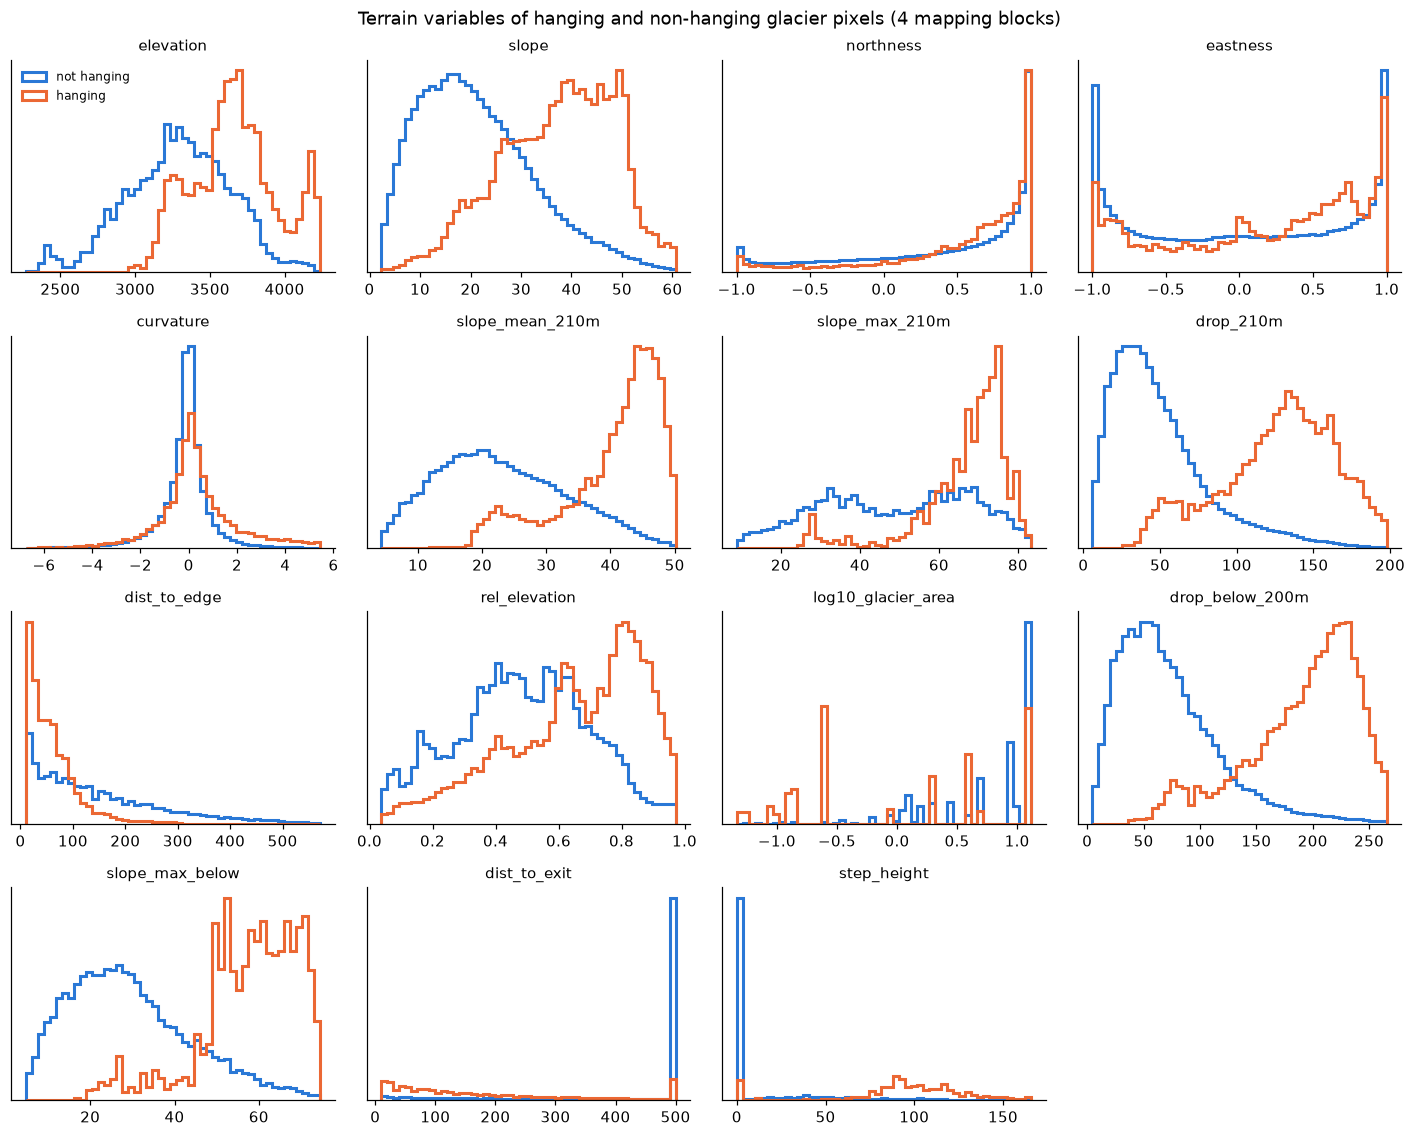

In [3]:
fig, axes = plt.subplots(4, 4, figsize=(13, 10.5))
for ax, name, values in zip(axes.flat, names, X.T):
    lo, hi = np.nanpercentile(values, [0.5, 99.5])
    bins = np.linspace(lo, hi, 50)
    ax.hist(values[y == 0], bins, density=True, histtype="step", lw=2, color=C_NOT, label="not hanging")
    ax.hist(values[y == 1], bins, density=True, histtype="step", lw=2, color=C_HANG, label="hanging")
    ax.set_title(name, fontsize=10)
    ax.set_yticks([])
for ax in axes.flat[len(names):]:
    ax.axis("off")
axes.flat[0].legend(fontsize=8, frameon=False)
fig.suptitle("Terrain variables of hanging and non-hanging glacier pixels (4 mapping blocks)")
fig.tight_layout()
fig.savefig(FIG / "03_feature_distributions.png", dpi=150)

## 3. Spatial cross-validation (leave one block out)

The out-of-fold probabilities of the 4 folds are pooled to compute the scores: with only a few
hanging glaciers per block, scores per block are noisy and are shown only for information.

A mapped glacier counts as **detected** when at least 25 % of its pixels have an out-of-fold probability ≥ 0.5.

**Which variables?** The same cross-validation is run with three sets of variables: the 11 variables of the
neighbourhood (first version), all 15 (adding the 4 variables of the path downslope, see `src/downslope.py`),
and all except the area of the SGI unit.

In [4]:
def make_forest():
    return RandomForestClassifier(n_estimators=200, min_samples_leaf=20, max_features="sqrt",
                                  class_weight="balanced_subsample", n_jobs=-1, random_state=0)


def cross_validate(X, y, b):
    """Out-of-fold probability of 'hanging' for every pixel, and the forest of each fold."""
    proba, forests = np.zeros(len(y)), {}
    for k in np.unique(b):
        test = b == k
        forests[k] = make_forest().fit(X[~test], y[~test])
        proba[test] = forests[k].predict_proba(X[test])[:, 1]
    return proba, forests


def detected(p):
    """Share of the pixels of each mapped polygon with probability >= 0.5, and the detected flag."""
    P = np.full(dem.shape, np.nan)
    P[train] = p
    share = np.array([np.mean(P[polygon_id == i] >= 0.5) if n else np.nan
                      for i, n in zip(range(1, len(polygons) + 1), polygons["pixels"])])
    return share, share >= 0.25


col = {n: i for i, n in enumerate(names)}
downslope_vars = ["drop_below_200m", "slope_max_below", "dist_to_exit", "step_height"]
variable_sets = {
    "neighbourhood only (11)": [n for n in names if n not in downslope_vars],
    "all variables (15)": names,
    "all but glacier area (14)": [n for n in names if n != "log10_glacier_area"],
}
mapped = polygons["pixels"] > 0
large, small = mapped & polygons["inside_large"], mapped & ~polygons["inside_large"]
results = {}
for label, subset in variable_sets.items():
    results[label] = cross_validate(X[:, [col[n] for n in subset]], y, b)
    p = results[label][0]
    _, det = detected(p)
    print(f"{label:>26}: AP {average_precision_score(y, p):.3f} | precision {y[p >= 0.5].mean():.2f}, "
          f"recall {np.mean(p[y == 1] >= 0.5):.2f} | detected: separate small units {det[small].sum()}/{small.sum()}, "
          f"parts of glaciers > 1 km² {det[large].sum()}/{large.sum()}")

   neighbourhood only (11): AP 0.421 | precision 0.55, recall 0.26 | detected: separate small units 8/15, parts of glaciers > 1 km² 0/12


        all variables (15): AP 0.516 | precision 0.54, recall 0.31 | detected: separate small units 8/15, parts of glaciers > 1 km² 1/12


 all but glacier area (14): AP 0.433 | precision 0.44, recall 0.44 | detected: separate small units 8/15, parts of glaciers > 1 km² 9/12


With the glacier area, the forest takes a shortcut: *small unit = hanging, large glacier = not hanging*.
This gives the best pixel score, but it misses almost every hanging part inside a large outline, which is
exactly what the research question asks for. Without it, the forest must recognise a hanging glacier from the
terrain alone; precision drops a little but most hanging parts of large glaciers are found.
**The model without the glacier area is used from here on.**

Simple **baselines** show what the forest adds: a single variable used as the score
(the local slope, or the height of the step below the glacier's lower edge).

In [5]:
main_vars = variable_sets["all but glacier area (14)"]
Xm = X[:, [col[n] for n in main_vars]]
proba, forests = results["all but glacier area (14)"]

scores = {
    "random forest": proba,
    "slope only": X[:, col["slope"]],
    "step height only": X[:, col["step_height"]],
}
print(f"prevalence (AP of a random guess): {y.mean():.3f}")
for label, s in scores.items():
    print(f"average precision, {label:>28}: {average_precision_score(y, s):.3f}")
print("per block (random forest):",
      {int(k): round(average_precision_score(y[b == k], proba[b == k]), 3) for k in np.unique(b)})

prevalence (AP of a random guess): 0.044
average precision,                random forest: 0.433
average precision,                   slope only: 0.188
average precision,             step height only: 0.368
per block (random forest): {1: 0.208, 2: 0.588, 3: 0.386, 4: 0.567}


threshold 0.5: precision 0.44, recall 0.44
  8,615 true positives, 10,878 false positives, 11,044 missed hanging pixels


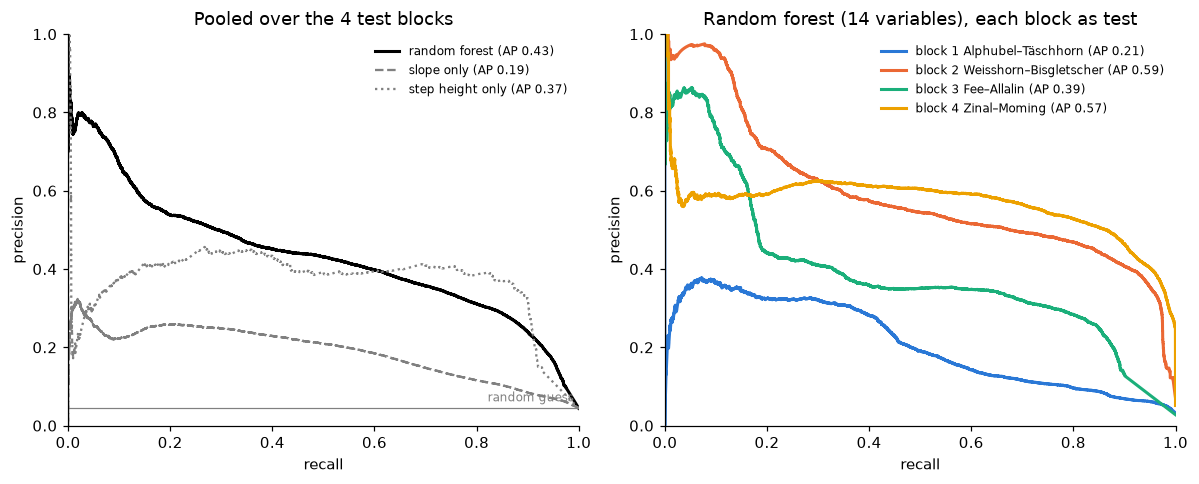

In [6]:
pred = proba >= 0.5
tp, fp, fn = (pred & (y == 1)).sum(), (pred & (y == 0)).sum(), (~pred & (y == 1)).sum()
print(f"threshold 0.5: precision {tp / (tp + fp):.2f}, recall {tp / (tp + fn):.2f}")
print(f"  {tp:,} true positives, {fp:,} false positives, {fn:,} missed hanging pixels")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ax = axes[0]
for (label, s), ls in zip(scores.items(), ["-", "--", ":"]):
    p, r, _ = precision_recall_curve(y, s)
    ax.plot(r, p, ls, color="black" if label == "random forest" else "grey", lw=2 if ls == "-" else 1.5,
            label=f"{label} (AP {average_precision_score(y, s):.2f})")
ax.axhline(y.mean(), color="grey", lw=0.8)
ax.text(0.99, y.mean() + 0.01, "random guess", ha="right", va="bottom", fontsize=8, color="grey")
ax.set(xlabel="recall", ylabel="precision", xlim=(0, 1), ylim=(0, 1), title="Pooled over the 4 test blocks")
ax.legend(fontsize=8, frameon=False)

ax = axes[1]
for k in np.unique(b):
    p, r, _ = precision_recall_curve(y[b == k], proba[b == k])
    ax.plot(r, p, color=C_BLOCK[k], lw=2,
            label=f"block {k} {blocks.set_index('block_id').loc[k, 'name']} "
                  f"(AP {average_precision_score(y[b == k], proba[b == k]):.2f})")
ax.set(xlabel="recall", ylabel="precision", xlim=(0, 1), ylim=(0, 1), title="Random forest (14 variables), each block as test")
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(FIG / "03_precision_recall.png", dpi=150)

## 4. Detection of each mapped hanging glacier

The question is about detecting **glaciers**, not pixels (detected = at least 25 % of the polygon's
pixels with an out-of-fold probability ≥ 0.5). False alarms are grouped into
patches of connected pixels; patches larger than 1 ha are the places to look at again on the imagery
(either model errors or hanging glaciers missed by the manual mapping).

In [7]:
P = np.full(dem.shape, np.nan)
P[train] = proba

polygons["detected_share"], polygons["detected"] = detected(proba)
in_blocks = polygons[mapped]
print(f"{in_blocks['detected'].sum()} of {len(in_blocks)} mapped hanging glaciers detected")
for c in (1, 2, 3):
    sub = in_blocks[in_blocks["confidence"] == c]
    print(f"  confidence {c}: {sub['detected'].sum()} of {len(sub)}")
in_blocks[["glacier", "glacier_area_km2", "front_type", "confidence", "pixels", "detected_share"]].sort_values("detected_share")

17 of 27 mapped hanging glaciers detected
  confidence 1: 4 of 10
  confidence 2: 8 of 10
  confidence 3: 5 of 7


,glacier,glacier_area_km2,front_type,confidence,pixels,detected_share
24,Chessjengletscher NW,0.238808,cliff,1,584,0.000000
19,Kingletscher S,0.842700,cliff,1,569,0.000000
4,Grand Gendarme,0.012573,ramp,2,116,0.008621
8,Blanc de Moming,0.020173,cliff,1,205,0.014634
1,Hohlichtpass,0.097019,cliff,3,407,0.029484
25,Fluchthorn W,0.252200,cliff,1,1979,0.051036
18,Glacier de Zinal,12.202934,cliff,1,347,0.172911
3,Bisgletscher,3.822854,ramp,3,810,0.229630
23,Alphubel,0.053373,ramp,1,509,0.235756
2,Bisgletscher,3.822854,ramp,2,1820,0.243956


In [8]:
false_alarm = (P >= 0.5) & (hanging == 0) & train
patches, n = ndimage.label(false_alarm)
sizes = ndimage.sum(false_alarm, patches, range(1, n + 1)) * DEM_RES**2 / 1e4   # ha
big = np.flatnonzero(sizes >= 1) + 1
print(f"{n} false-alarm patches, {len(big)} larger than 1 ha "
      f"({sizes[sizes >= 1].sum():.0f} ha of {sizes.sum():.0f} ha of false alarms)")

632 false-alarm patches, 27 larger than 1 ha (70 ha of 109 ha of false alarms)


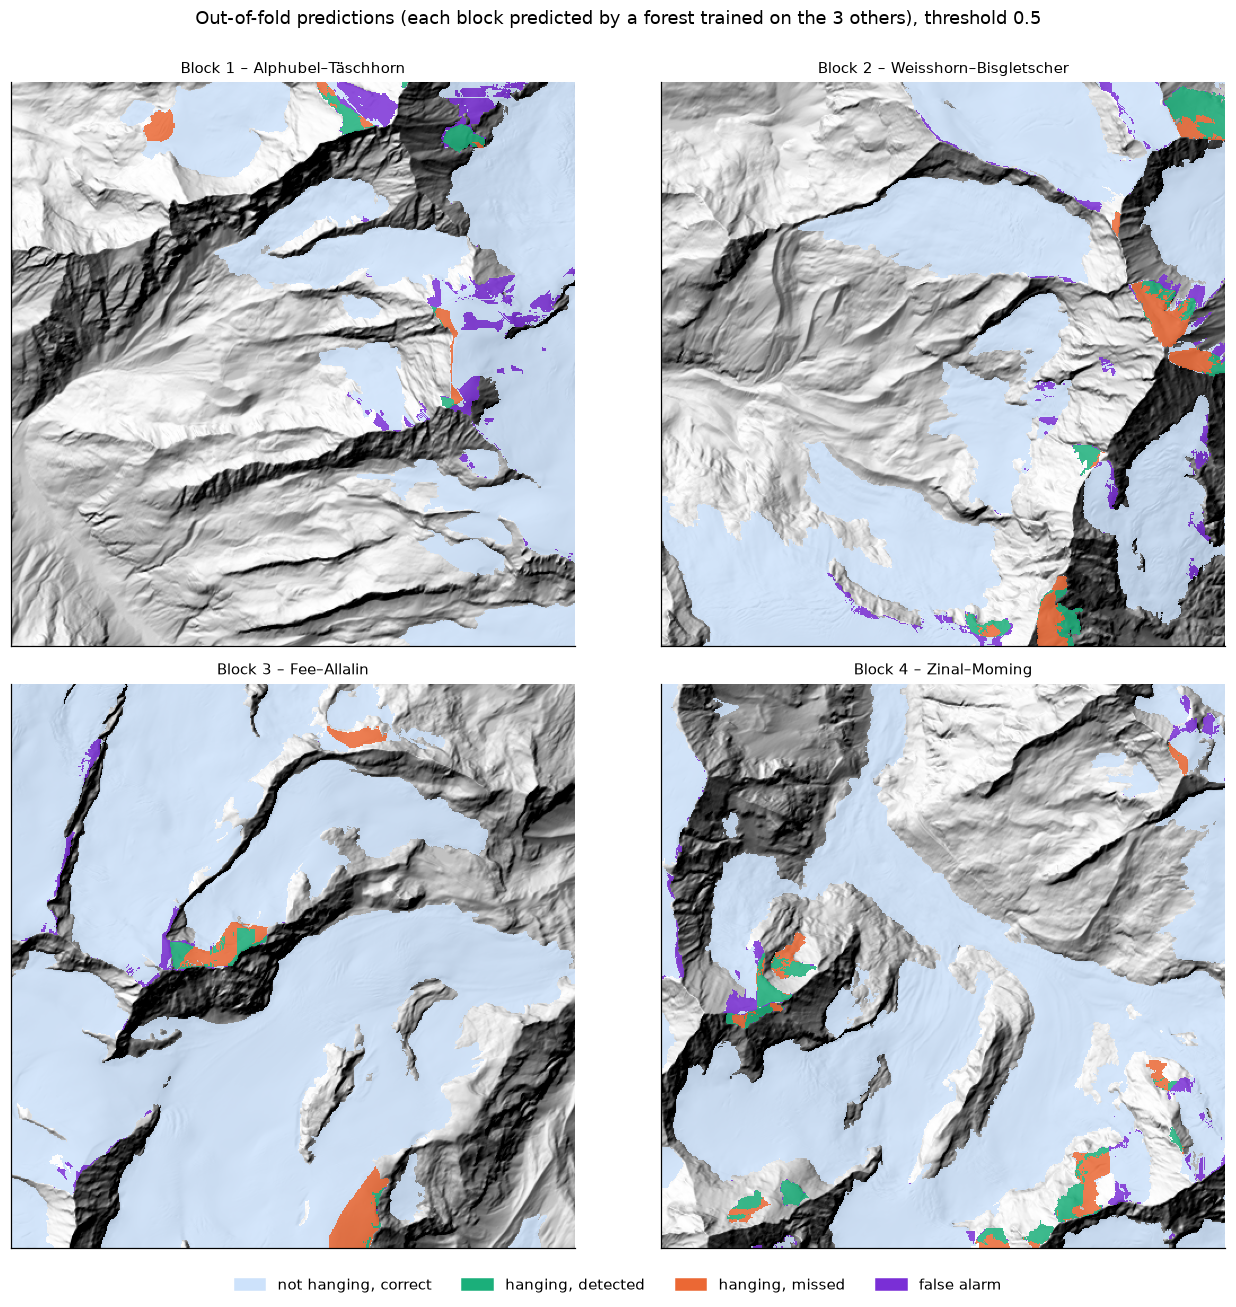

In [9]:
shade = hillshade(dem, DEM_RES)
fig, axes = plt.subplots(2, 2, figsize=(12, 12))
for ax, (_, blk) in zip(axes.flat, blocks.iterrows()):
    x0, y0, x1, y1 = blk.geometry.bounds
    r0, c0 = ~transform * (x0, y1)
    r1, c1 = ~transform * (x1, y0)
    win = np.s_[int(c0):int(c1), int(r0):int(r1)]
    ext = (x0, x1, y0, y1)
    ax.imshow(shade[win], cmap="gray", extent=ext, vmin=-0.2, vmax=1)
    cls = np.full(shade[win].shape, np.nan)
    h, p, t = hanging[win] == 1, P[win] >= 0.5, train[win]
    cls[t & ~h & ~p] = 0          # correct negative
    cls[t & h & p] = 1            # hit
    cls[t & h & ~p] = 2           # missed
    cls[t & ~h & p] = 3           # false alarm
    from matplotlib.colors import ListedColormap
    ax.imshow(cls, cmap=ListedColormap(["#cde2fb", "#1baf7a", "#eb6834", "#7a2fd6"]), vmin=-0.5, vmax=3.5,
              extent=ext, interpolation="nearest", alpha=0.85)
    ax.set_title(f"Block {blk.block_id} – {blk['name']}", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ["#cde2fb", "#1baf7a", "#eb6834", "#7a2fd6"]]
fig.legend(handles, ["not hanging, correct", "hanging, detected", "hanging, missed", "false alarm"],
           loc="lower center", ncol=4, frameon=False)
fig.suptitle("Out-of-fold predictions (each block predicted by a forest trained on the 3 others), threshold 0.5")
fig.tight_layout(rect=(0, 0.03, 1, 0.98))
fig.savefig(FIG / "03_errors_by_block.png", dpi=150)

## 5. Sensitivity to doubtful labels

The polygons with confidence 1 (doubtful) are removed from training and testing.

In [10]:
keep = conf != 1
proba_sure, _ = cross_validate(Xm[keep], y[keep], b[keep])
print(f"without confidence-1 polygons: {y[keep].sum():,} hanging pixels, "
      f"AP {average_precision_score(y[keep], proba_sure):.3f} "
      f"(random guess {y[keep].mean():.3f}); all polygons: AP {average_precision_score(y, proba):.3f}")

without confidence-1 polygons: 12,463 hanging pixels, AP 0.290 (random guess 0.029); all polygons: AP 0.433


## 6. Which variables matter?

Permutation importance on the test block of each fold (drop in average precision when a variable is
shuffled), on a random sample of 40,000 pixels per block. Unlike the built-in impurity importance, it
is measured on data the forest has not seen.

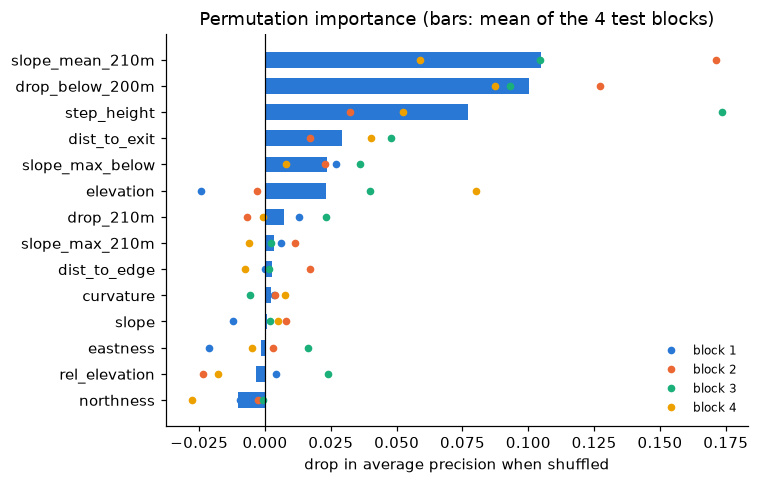

In [11]:
rng = np.random.default_rng(0)
imp = []
for k, forest in forests.items():
    idx = np.flatnonzero(b == k)
    idx = rng.choice(idx, size=min(40_000, len(idx)), replace=False)
    r = permutation_importance(forest, Xm[idx], y[idx], scoring="average_precision", n_repeats=3,
                               random_state=0, n_jobs=1)
    imp.append(r.importances_mean)
imp = np.array(imp)
order = np.argsort(imp.mean(axis=0))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(np.array(main_vars)[order], imp.mean(axis=0)[order], color="#2a78d6", height=0.6)
for k, row in zip(forests, imp):
    ax.plot(row[order], range(len(main_vars)), "o", ms=4, color=C_BLOCK[k], label=f"block {k}")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("drop in average precision when shuffled")
ax.set_title("Permutation importance (bars: mean of the 4 test blocks)")
ax.legend(fontsize=8, frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(FIG / "03_feature_importance.png", dpi=150)

## 7. Map of the whole massif

A forest trained on all 4 blocks (14 variables, no glacier area) predicts every glacier pixel of the study extent. Outside the
blocks there is no reference: this map is the candidate list to be ranked and checked.

outside the blocks: 3.43 km² predicted hanging of 114.2 km² of ice (3.0%)


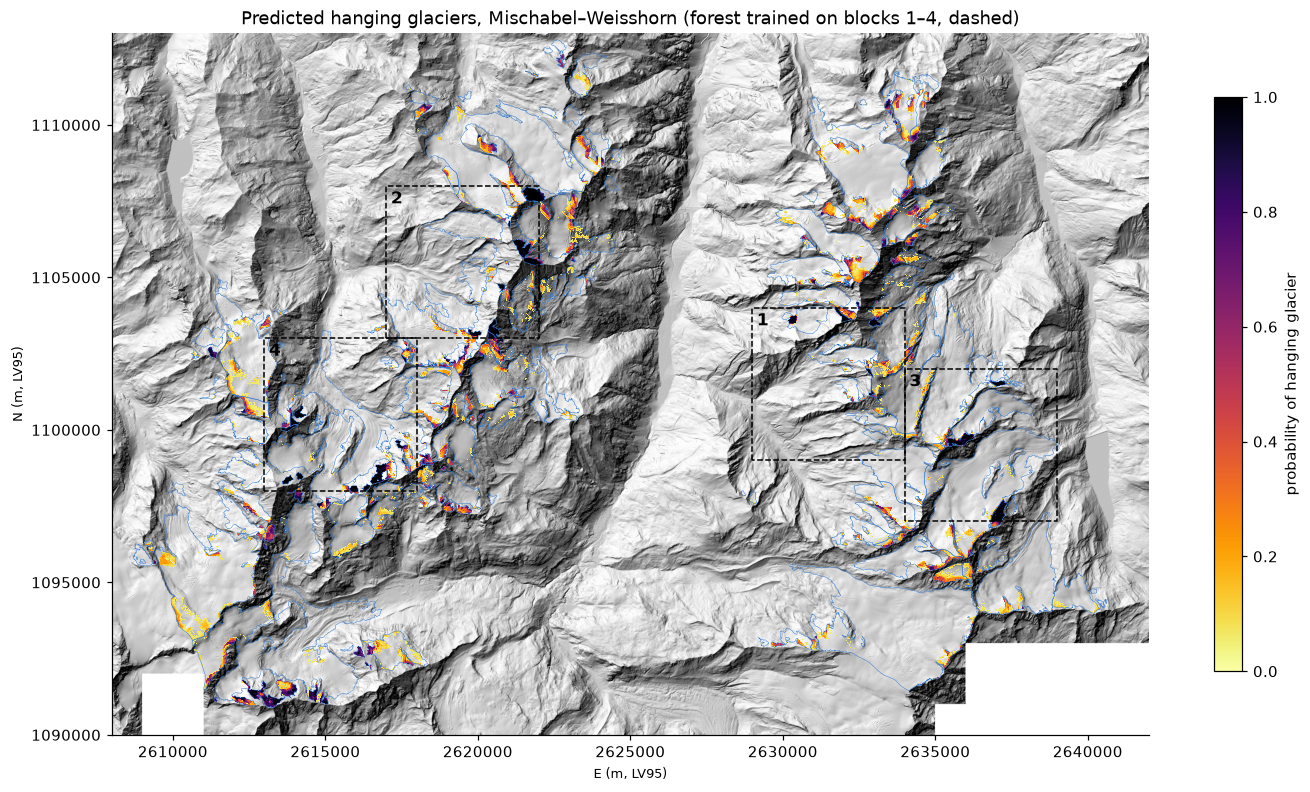

In [12]:
final = make_forest().fit(Xm, y)
prob_map = np.full(dem.shape, np.nan, "float32")
prob_map[ice] = final.predict_proba(F[[col[n] for n in main_vars]][:, ice].T)[:, 1]

with rasterio.open(PROCESSED / f"dem_{DEM_RES}m.tif") as src:
    profile = src.profile
profile.update(dtype="float32", nodata=np.nan, compress="deflate")
with rasterio.open(PROCESSED / f"hanging_probability_{DEM_RES}m.tif", "w", **profile) as dst:
    dst.write(prob_map, 1)

outside = ice & (block == 0)
print(f"outside the blocks: {(prob_map[outside] >= 0.5).sum() * DEM_RES**2 / 1e6:.2f} km² predicted hanging "
      f"of {outside.sum() * DEM_RES**2 / 1e6:.1f} km² of ice ({np.mean(prob_map[outside] >= 0.5):.1%})")

x0, y0 = transform * (0, dem.shape[0])
x1, y1 = transform * (dem.shape[1], 0)
fig, ax = plt.subplots(figsize=(13, 9))
ax.imshow(shade, cmap="gray", extent=(x0, x1, y0, y1), vmin=-0.2, vmax=1)
im = ax.imshow(np.where(prob_map >= 0.05, prob_map, np.nan), cmap="inferno_r", vmin=0, vmax=1,
               extent=(x0, x1, y0, y1), interpolation="nearest")
glaciers.boundary.plot(ax=ax, color="#2a78d6", lw=0.3)
blocks.boundary.plot(ax=ax, color="black", lw=1, ls="--")
for _, blk in blocks.iterrows():
    bx0, _, _, by1 = blk.geometry.bounds
    ax.text(bx0 + 150, by1 - 150, str(blk.block_id), va="top", fontsize=11, fontweight="bold")
fig.colorbar(im, ax=ax, shrink=0.6, label="probability of hanging glacier")
ax.set_title("Predicted hanging glaciers, Mischabel–Weisshorn (forest trained on blocks 1–4, dashed)")
ax.ticklabel_format(style="plain")
ax.set_xlabel("E (m, LV95)"); ax.set_ylabel("N (m, LV95)")
fig.tight_layout()
fig.savefig(FIG / "03_probability_map.png", dpi=150)